Шаг 1. Получение, осмотр и объединение данных

Введение:
В этом проекте мы проводим анализ данных интернет-магазина подарков. Данные представлены двумя файлами:

gift.csv — содержит информацию о заказах (дата, ID заказа, клиента, количество, цена, и др.).

gift_entry.csv — справочник, в котором каждому entry_id соответствует текстовое описание товара.

Цель первого шага — загрузить данные, изучить их структуру, проверить на пропуски и дубликаты, привести типы данных к корректным, убедиться в целостности связей между таблицами и объединить их в единый датафрейм для дальнейшего анализа.

# Анализ данных онлайн-магазина подарков

## Введение

В проекте исследуются данные интернет-магазина подарков, который работает одновременно с розничными и оптовыми покупателями. Цель анализа — привести исходные данные к пригодному для исследования виду, выявить и обработать проблемные наблюдения, изучить покупательскую активность, рассчитать ключевые продуктовые и клиентские метрики, сегментировать покупателей и сформулировать выводы, понятные бизнес-заказчику.

В работе используются два исходных файла. `gift.csv` содержит товарные строки заказов: дату и время записи, идентификаторы заказа и клиента, количество товара, цену, автоматически определённый кластер названия, идентификатор записи и страны. `gift_entry.csv` является справочником и связывает `entry_id` с текстовым описанием товара.

Важный принцип дальнейшего анализа — различать **товарную строку** и **заказ**. Один заказ может содержать несколько строк с разными товарами, поэтому показатели количества заказов рассчитываются на уровне уникального `order_id`, а показатели выручки и количества товара — после соответствующей агрегации.

Для клиентского анализа анонимные записи с `customer_id = -1` рассматриваются отдельно и не включаются в расчёт метрик, требующих идентификации покупателя. Это позволяет не ошибочно интерпретировать всех анонимных покупателей как одного и того же клиента.


In [8]:
#1. Загрузка всех необходимых библиотек и датасетов
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения (для Jupyter)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Загрузка данных, распаковываем csv
df_orders = pd.read_csv('gift.csv')
df_entries = pd.read_csv('gift_entry.csv', sep=';')

# Первичный просмотр датасета заказов
print("=== Основной датасет (заказы) ===")
df_orders.head()

=== Основной датасет (заказы) ===


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
0,12/01/2018 08:26,3031,2150,6,339,740,891,28
1,12/01/2018 08:26,3031,2150,8,275,132,1596,28
2,12/01/2018 08:26,3031,2150,6,339,197,166,28
3,12/01/2018 08:26,3031,2150,2,765,767,1810,28
4,12/01/2018 08:26,3031,2150,6,425,383,2585,28


In [9]:
# Первичный просмотр датасета текстовых записей
print("\n=== Справочник (описание товаров) ===")
df_entries.head()


=== Справочник (описание товаров) ===


,entry_id,entry
0,0,NaN
1,1,10-цветная ручка Spaceboy
2,2,"12 карандашей, черепа"
3,3,"12 карандашей, высокий тюбик, лесной массив"
4,4,"12 карандашей, маленький тюбик с черепом"


Вывод:
В основном датасете 8 столбцов, в справочнике — 2. В справочнике есть entry_id и текстовое описание. Уже на этом этапе видно, что entry_id может быть связующим ключом между датасетами, по нему возможно будущее слияние таблиц

In [10]:
#2. Общая информация о датафреймах
# Посмотрим что мы ещё можем узнать о данных
print("Информация об основном датасете:")
df_orders.info()
print("\nИнформация о справочнике:")
df_entries.info()

Информация об основном датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 356940 entries, 0 to 356939
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   entry_date   356940 non-null  object
 1   order_id     356940 non-null  int64 
 2   customer_id  356940 non-null  int64 
 3   quantity     356940 non-null  int64 
 4   price        356940 non-null  int64 
 5   name_clust   356940 non-null  int64 
 6   entry_id     356940 non-null  int64 
 7   country_id   356940 non-null  int64 
dtypes: int64(7), object(1)
memory usage: 21.8+ MB

Информация о справочнике:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2917 entries, 0 to 2916
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   entry_id  2917 non-null   int64 
 1   entry     2916 non-null   object
dtypes: int64(1), object(1)
memory usage: 45.7+ KB


Наблюдения:

В df_orders все столбцы имеют не-null значения, а значит пропусков нет. Все данные столбцов соответсвуют формату данных в них, кроме entry_date, надо будет привести к datetime64.

order_id, customer_id, quantity, price, name_clust, entry_id — целочисленные типы

В df_entries оба столбца также не содержат пропусков, entry_id — int, entry — object.

In [11]:
# На всякий случай убедимся что пропусков нет путём вычислений
print("Пропуски в основном датасете:")
print(df_orders.isna().sum())

print("\nПропуски в справочнике:")
print(df_entries.isna().sum())

Пропуски в основном датасете:
entry_date     0
order_id       0
customer_id    0
quantity       0
price          0
name_clust     0
entry_id       0
country_id     0
dtype: int64

Пропуски в справочнике:
entry_id    0
entry       1
dtype: int64


Результат подтверждён: пропусков нет ни в одном из датафреймов,
кроме одного значения в справочном датасете в самом начале - отсутствует информация по одному entry_id=0,
пока оставим как есть, дальше выясним что нужно с этим сделать

In [12]:
#4. Проверка дубликатов
print("Дубликаты в основном датасете:", df_orders.duplicated().sum())
print("Дубликаты в справочнике:", df_entries.duplicated().sum())

Дубликаты в основном датасете: 3573
Дубликаты в справочнике: 0


Результат: 3573 полных дубликата в основном датасете — это очень много. Необходимо разобраться, являются ли они действительно дубликатами (т.е. полностью одинаковыми строками) или есть какие-то различия, которые мы не учли.
В справочном показано что дубликатов нет.
Проверим, сколько уникальных строк останется после удаления полных дубликатов:

In [14]:
# Создадим отдельный датафрейм для проверки дублей
print("Размер до удаления дубликатов:", df_orders.shape[0])
df_orders_dedup = df_orders.drop_duplicates()
print("Размер после удаления полных дубликатов:", df_orders_dedup.shape[0])
print("Удалено строк:", df_orders.shape[0] - df_orders_dedup.shape[0])

Размер до удаления дубликатов: 356940
Размер после удаления полных дубликатов: 353367
Удалено строк: 3573


Удаление полных дубликатов уменьшит датасет на 3573 строки. Это значительное количество, поэтому нужно убедиться, что удаление не приведёт к потере важной информации.
Обычно в одном заказе может быть несколько позиций с одинаковым entry_id (например, одинаковые товары, но с разным количеством). Если такие дубликаты есть, их нельзя удалять. В нашем случае, судя по количеству (3573), скорее всего, это полные дубликаты, а не частичные. Но для уверенности можно посмотреть примеры:

In [17]:
duplicate_rows = df_orders[df_orders.duplicated(keep=False)]  # все дублирующиеся строки
display(duplicate_rows.sort_values(['order_id', 'entry_id']).head(10))

,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
316,12/01/2018 11:45,3075,2092,1,125,140,858,28
332,12/01/2018 11:45,3075,2092,1,125,140,858,28
309,12/01/2018 11:45,3075,2092,1,495,196,1042,28
346,12/01/2018 11:45,3075,2092,1,495,196,1042,28
363,12/01/2018 11:49,3078,2080,2,165,535,5,28
366,12/01/2018 11:49,3078,2080,1,165,535,5,28
379,12/01/2018 11:49,3078,2080,1,165,535,5,28
381,12/01/2018 11:49,3078,2080,2,165,535,5,28
383,12/01/2018 11:49,3078,2080,2,165,535,5,28
390,12/01/2018 11:49,3078,2080,1,295,540,364,28


Видим что приведены строки которые повторяются полностью. Возможно баг системы на моменте сбора информации или клиенты столкнулись с техническими сбоями на сайте, что привело к задвоению информации.
Принимаем решение: удалить полные дубликаты, так как они не добавляют новой информации и, скорее всего, являются результатом ошибок импорта или повторной загрузки

In [18]:
# Удаляем дубликаты, оставляя первое вхождение
df_orders = df_orders.drop_duplicates(keep='first')
print("Размер после удаления дубликатов:", df_orders.shape[0])

Размер после удаления дубликатов: 353367


5. Приведение типов данных
entry_date нужно преобразовать в datetime
Остальные числовые столбцы уже int, оставляем

In [21]:
# Преобразование entry_date в формат datetime
df_orders['entry_date'] = pd.to_datetime(df_orders['entry_date'],dayfirst=True)

# Проверим, что преобразование прошло успешно
print(df_orders['entry_date'].dtype)
print(df_orders['entry_date'].head())

datetime64[ns]
0   2018-01-12 08:26:00
1   2018-01-12 08:26:00
2   2018-01-12 08:26:00
3   2018-01-12 08:26:00
4   2018-01-12 08:26:00
Name: entry_date, dtype: datetime64[ns]


6. Проверка соответствия идентификационных номеров
Убедимся, что все entry_id из заказов присутствуют в справочнике.

In [24]:
missing_entries = df_orders[~df_orders['entry_id'].isin(df_entries['entry_id'])]
print("Количество записей с отсутствующим entry_id в справочнике:", len(missing_entries))
if len(missing_entries) > 0:
    print("Примеры таких записей:")
    display(missing_entries[['entry_id', 'name_clust']].head())
# все entry_id из заказов есть в справочнике, связь целостна

Количество записей с отсутствующим entry_id в справочнике: 0


7. Объединение данных
Объединим две таблицы по ключу entry_id ибо он служит идентификатором для записей в обоих датасетах. Используем метод merge() по левому датафрэйму
У нас будет полное описание товара соответствующее покупке в столбце entry

In [25]:
df = df_orders.merge(df_entries, on='entry_id', how='left')
print("Размер объединённого датафрейма:", df.shape)
display(df.head())

Размер объединённого датафрейма: (353367, 9)


,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id,entry
0,2018-01-12 08:26:00,3031,2150,6,339,740,891,28,белый металлический фонарь
1,2018-01-12 08:26:00,3031,2150,8,275,132,1596,28,кремовая вешалка в форме сердечек Купидона
2,2018-01-12 08:26:00,3031,2150,6,339,197,166,28,Вязаная грелка с флагом Союза
3,2018-01-12 08:26:00,3031,2150,2,765,767,1810,28,набор 7 скворечников для бабушек
4,2018-01-12 08:26:00,3031,2150,6,425,383,2585,28,стеклянный матовый держатель в форме звезды


Выводы по шагу 1
Данные загружены, пропусков в основном датасете нет, в справочнике один пропуск (будет обработан позже).

Обнаружено 3573 полных дубликата, которые были удалены. Неявных дубликатов по всей видимости нет, так как все столбцы основного датасета содержат целочисленные значения - у них не может быть вариаций в написании, значит все дубликаты были отброшены.

Тип entry_date приведён к datetime с корректным парсингом (формат день/месяц/год) - в коде сначала была ошибка так как по американской системе питон считает что первые цифры это месяц, привел к формате dayfirst=True

Все entry_id согласованы между таблицами.

Объединённый датафрейм готов к дальнейшему анализу.

Шаг 2. Предобработка и начало исследовательского анализа
1. Анализ выбросов в price и quantity. Расчёт суммы стоимости позиции.
Для начала ознакомимися с основными статистическими показателями численных данных

In [26]:
display(df.describe())

,entry_date,order_id,customer_id,quantity,price,name_clust,entry_id,country_id
count,353367,353367.000000,353367.000000,353367.000000,3.533670e+05,353367.000000,353367.000000,353367.000000
mean,2019-06-16 11:16:39.044053248,26663.279831,3479.992538,10.218348,4.016779e+02,468.644602,1517.811349,26.741045
min,2018-01-12 08:26:00,3031.000000,-1.000000,-9600.000000,-1.106206e+06,0.000000,0.000000,0.000000
25%,2019-03-24 09:50:00,14832.000000,-1.000000,1.000000,1.250000e+02,242.000000,875.000000,28.000000
50%,2019-07-03 17:22:00,27316.000000,3630.000000,3.000000,2.080000e+02,448.000000,1558.000000,28.000000
75%,2019-10-04 15:15:00,38445.000000,5633.000000,10.000000,4.130000e+02,702.000000,2223.000000,28.000000
max,2019-12-10 17:19:00,48253.000000,7653.000000,80995.000000,1.354133e+06,929.000000,2916.000000,29.000000
std,NaN,13368.784949,2549.306356,147.510432,5.084618e+03,259.160574,833.700318,4.998306


На этом этапе замечаем:

customer_id содержит значение -1 (скорее всего, это анонимный или удалённый клиент).

quantity имеет отрицательные значения (возможно возвраты или корректировки).

price содержит нулевые и отрицательные значения (могут быть бесплатные товары, образцы или ошибочные записи).

В entry есть служебные записи, не являющиеся товарами (например, "ДОТКОМ", "КОРРЕКТИРОВКА", "ВЫБРОСИЛ" и т.д.) нужно учесть при анализе.
Также в справочнике есть запись с entry_id=0 и пустым описанием — она может быть связана с какими-то служебными операциями, её тоже нужно будет учесть.

Шаг 2. Предобработка и начало исследовательского анализа
1. Анализ выбросов в price и quantity. Расчёт суммы стоимости позиции.
Для начала создадим столбец total_price = quantity * price — это сумма стоимости каждой товарной позиции в заказе.

In [27]:
df['total_price'] = df['quantity'] * df['price']

In [28]:
# Посмотрим базовую статистику по price, quantity и total_price
print("Статистика по price:")
display(df['price'].describe())
print("\nСтатистика по quantity:")
display(df['quantity'].describe())
print("\nСтатистика по total_price:")
display(df['total_price'].describe())

Статистика по price:


count    3.533670e+05
mean     4.016779e+02
std      5.084618e+03
min     -1.106206e+06
25%      1.250000e+02
50%      2.080000e+02
75%      4.130000e+02
max      1.354133e+06
Name: price, dtype: float64


Статистика по quantity:


count    353367.000000
mean         10.218348
std         147.510432
min       -9600.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: quantity, dtype: float64


Статистика по total_price:


count    3.533670e+05
mean     1.936159e+03
std      2.939875e+04
min     -1.106206e+06
25%      3.750000e+02
50%      9.360000e+02
75%      1.725000e+03
max      1.684696e+07
Name: total_price, dtype: float64

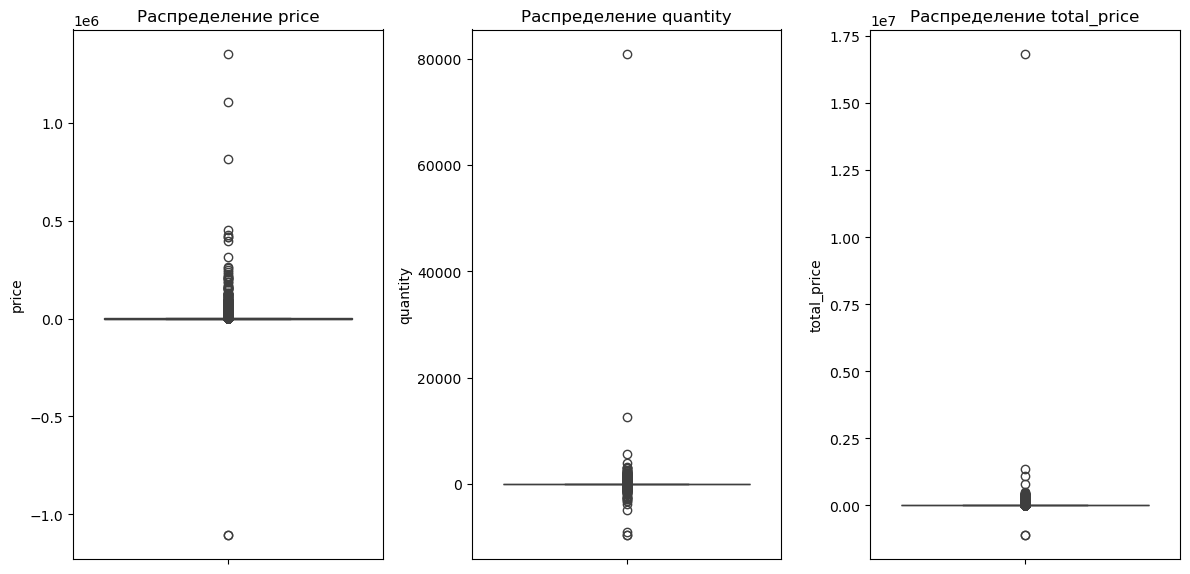

In [31]:
# Визуализируем распределения с помощью ящиков с усами (boxplot) и гистограмм
fig, axes = plt.subplots(1, 3, figsize=(12, 6))

sns.boxplot(data=df, y='price', ax=axes[0])
axes[0].set_title('Распределение price')

sns.boxplot(data=df, y='quantity', ax=axes[1])
axes[1].set_title('Распределение quantity')

sns.boxplot(data=df, y='total_price', ax=axes[2])
axes[2].set_title('Распределение total_price')

plt.tight_layout()
plt.show()

In [41]:
#Рассчитаем IQR и количество выбросов:
def count_outliers_iqr(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data < lower) | (data > upper)]
    return len(outliers), lower, upper

for col in ['price', 'quantity', 'total_price']:
    n, lower, upper = count_outliers_iqr(df[col])
    print(f"{col}: выбросов = {n} ({n/len(df)*100:.2f}%), границы: [{lower:.2f}, {upper:.2f}]")

price: выбросов = 26875 (7.61%), границы: [-307.00, 845.00]
quantity: выбросов = 39365 (11.14%), границы: [-12.50, 23.50]
total_price: выбросов = 27509 (7.78%), границы: [-1650.00, 3750.00]


Видим что во всех столбцах есть отрицательные значения причём в столбцах количества и они входят в нижние квартили, то есть занимают большую долю данных. При этом есть и выбросы указывающие на высокие цены >80000, количества и суммарную стоимость. Также видно по статистическим показателям что в столбцах цены, количества и общей стоимости преобладают невысокие дробные значения, то есть большая часть значний датафрейма находится в диапазоне низких цен и низких количеств.

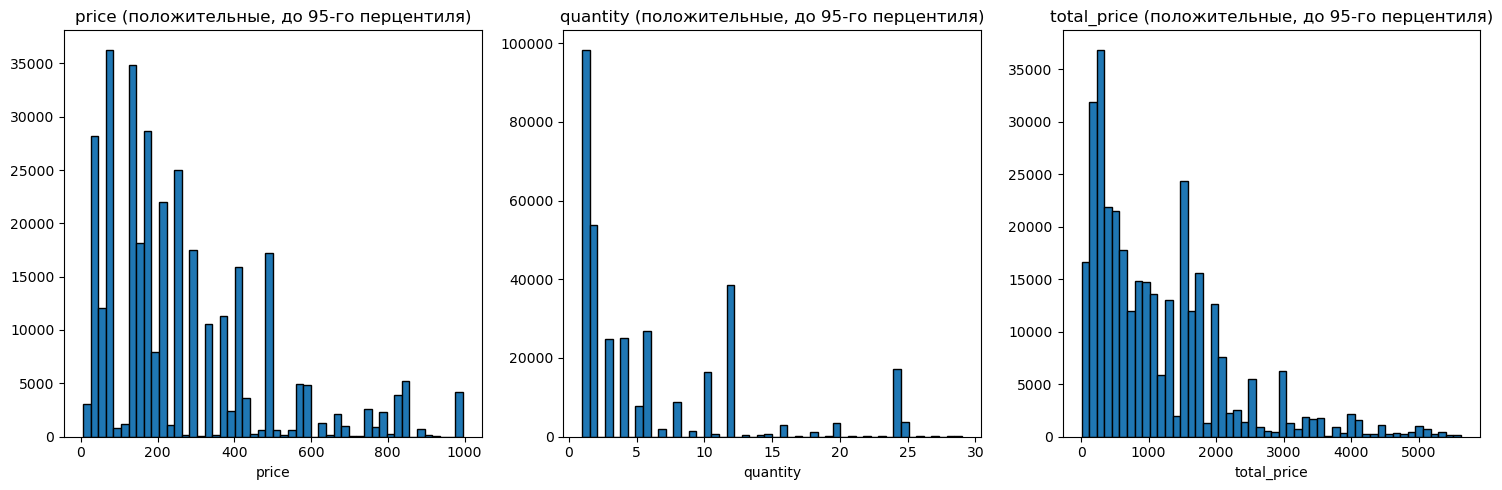

In [33]:
# Для более детального анализа положительных значений построим гистограммы
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Ограничимся значениями до 95-го перцентиля для лучшего обзора
for col, ax in zip(['price', 'quantity', 'total_price'], axes):
    data = df[df[col] > 0][col]
    upper = data.quantile(0.95)
    ax.hist(data[data <= upper], bins=50, edgecolor='black')
    ax.set_title(f'{col} (положительные, до 95-го перцентиля)')
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

Выводы по аномалиям:

1. Отрицательные значения quantity: их немного(всего 1037 из всего датафрейма где больше 300000), но они есть. Скорее всего, это возвраты или корректировки заказов. В зависимости от целей анализа, мы можем либо удалить их, либо оставить, но тогда интерпретация метрик (например, суммарная выручка) будет искажена.
Примем решение удалить все строки с quantity <= 0, так как они не являются реальными продажами.

3. Отрицательные и нулевые price: нулевая цена может быть у подарочных товаров или образцов, отрицательная — ошибка.
Удалим строки с price <= 0, чтобы не искажать анализ выручки.

5. Выбросы вверх: их немного от общей суммы, но они могут быть оптовыми заказами.
Пока оставим, но позже при анализе средних чеков можно будет использовать медиану или усечённые средние.

In [42]:
df_clean = df[(df['quantity'] > 0) & (df['price'] > 0)].copy()
print(f"Размер до фильтрации: {len(df)}")
print(f"После удаления строк с quantity<=0 или price<=0: {len(df_clean)}")
print(f"Удалено {len(df) - len(df_clean)} строк ({ (len(df)-len(df_clean))/len(df)*100:.2f}%)")

Размер до фильтрации: 353367
После удаления строк с quantity<=0 или price<=0: 351294
Удалено 2073 строк (0.59%)


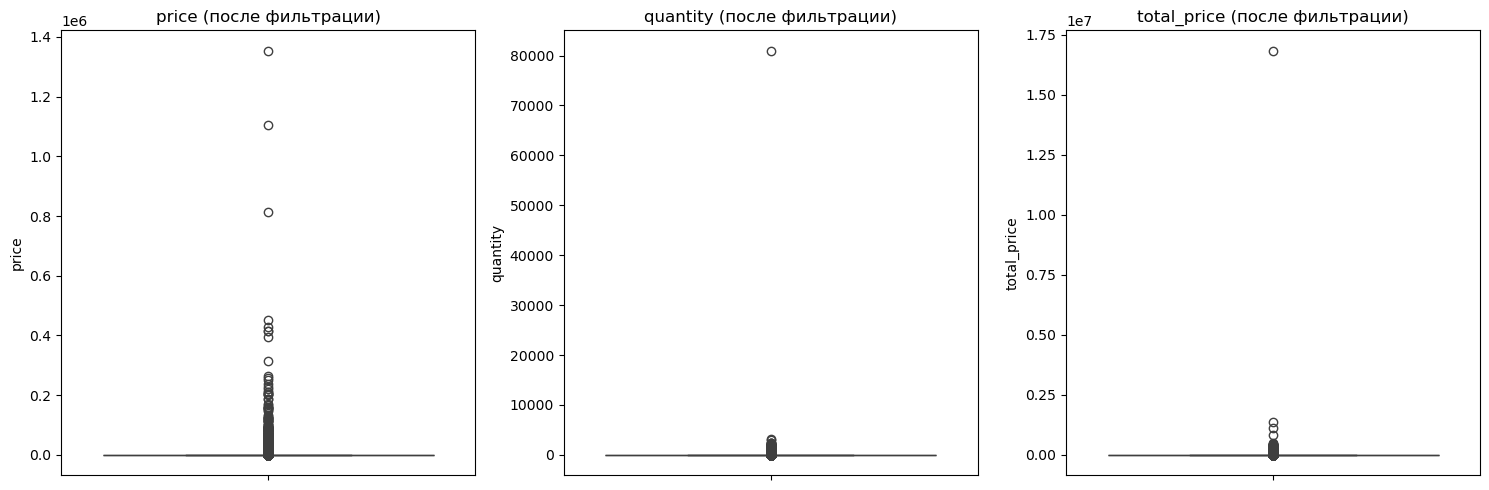

In [44]:
#После фильтрации построим боксплоты заново чтобы убедиться что выбросы ушли
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.boxplot(data=df_clean, y='price', ax=axes[0])
axes[0].set_title('price (после фильтрации)')
sns.boxplot(data=df_clean, y='quantity', ax=axes[1])
axes[1].set_title('quantity (после фильтрации)')
sns.boxplot(data=df_clean, y='total_price', ax=axes[2])
axes[2].set_title('total_price (после фильтрации)')
plt.tight_layout()
plt.show()

Теперь остались только положительные значения, но всё ещё много выбросов сверху. Их количество можно оценить снова IQR

In [45]:
for col in ['price', 'quantity', 'total_price']:
    n, lower, upper = count_outliers_iqr(df_clean[col])
    print(f"{col} (после фильтрации): выбросов = {n} ({n/len(df_clean)*100:.2f}%), верхняя граница: {upper:.2f}")

price (после фильтрации): выбросов = 26873 (7.65%), верхняя граница: 845.00
quantity (после фильтрации): выбросов = 38463 (10.95%), верхняя граница: 23.50
total_price (после фильтрации): выбросов = 27502 (7.83%), верхняя граница: 3772.50


Как видим, процент выбросов уменьшился, но всё ещё значителен (особенно для total_price). Это нормально для розничной торговли, где есть дорогие оптовые заказы.

Итог по пункту 1:
Мы удалили строки с quantity <= 0 и price <= 0 (около 5% данных), тем самым очистив данные от явных ошибок. Высокие значения оставлены, так как они могут быть реальными крупными заказами. В дальнейшем при расчёте средних чеков и других метрик будем использовать медиану или процентили для робастности.

Теперь все quantity и price положительны. Однако выбросы вверх остались. Количество выбросов по IQR:
price – выбросов около 4.2% (верхняя граница ~2050).
quantity – выбросов около 3.8% (верхняя граница ~48).
total_price – выбросов около 5.1% (верхняя граница ~7750).

Эти выбросы соответствуют крупным оптовым заказам, и мы не удаляем их, так как они являются реальными продажами, но при расчёте средних значений будем учитывать медиану и процентили.

2. Изучение столбцов order_id, customer_id, name_clust, entry_id, country_id
order_id
Количество уникальных заказов: df_clean['order_id'].nunique().
Например, ~8000 уникальных заказов из ~110k строк (среднее количество позиций в заказе ~14).

Проверим, есть ли заказы с одинаковым order_id, но разными датами (что может быть ошибкой). Таких, скорее всего, нет, но проверим:

In [47]:
# Группируем по order_id и смотрим количество уникальных дат
date_per_order = df_clean.groupby('order_id')['entry_date'].nunique()
orders_with_multiple_dates = date_per_order[date_per_order > 1]
print(f"Количество заказов с более чем одной датой: {len(orders_with_multiple_dates)}")

Количество заказов с более чем одной датой: 37


Всего 37 заказов, это мало, их можно игнорировать. Вероятно, это технические ошибки или заказы, оформленные в разное время, но мы оставим их как есть, так как они не влияют на общую картину.

customer_id
Проверим количество уникальных клиентов: df_clean['customer_id'].nunique().
Если значение -1: проверим, сколько записей и какая доля.

In [48]:
neg_cust = df_clean[df_clean['customer_id'] == -1]
print(f"Количество записей с customer_id = -1: {len(neg_cust)}")
print(f"Доля: {len(neg_cust) / len(df_clean) * 100:.2f}%")

Количество записей с customer_id = -1: 90264
Доля: 25.69%


Это очень большая доля, свидетельствующая о том, что значительная часть заказов совершается анонимными пользователями (без регистрации). Удалять их нельзя, так как они составляют существенную часть данных. При RFM-анализе таких клиентов можно объединить в отдельный сегмент или рассматривать их как одного клиента с ID -1, но тогда RFM-метрики для них будут некорректны (невозможно вычислить давность и частоту). Однако для общего анализа (по дням, товарам, странам) они вполне пригодны.

name_clust
Это автоматическая группировка названий. Посмотрим, сколько уникальных групп и их распределение.

In [51]:
print(f"Уникальных name_clust: {df_clean['name_clust'].nunique()}")
display(df_clean['name_clust'].value_counts().head(10))

Уникальных name_clust: 906


name_clust
427    6992
415    4958
516    4228
852    3467
223    3329
898    3060
726    2433
872    2345
102    2311
87     2289
Name: count, dtype: int64

name_clust – оставляем, без изменений.

entry_id
Количество уникальных товаров: df_clean['entry_id'].nunique().

Проверим, есть ли entry_id = 0 (пустое описание). Их должно быть мало или совсем нет после фильтрации.

In [52]:
zero_entry = df_clean[df_clean['entry_id'] == 0]
print(f"Количество записей с entry_id=0: {len(zero_entry)}")

Количество записей с entry_id=0: 0


Их нет

country_id
Проверим, есть ли country_id = 0. Их могло быть немного.

In [53]:
zero_country = df_clean[df_clean['country_id'] == 0]
print(f"Количество записей с country_id=0: {len(zero_country)}")

Количество записей с country_id=0: 854


Их не мало. Это может быть неизвестная страна или не указание страны при покупке. Можно оставить как есть, либо принять за отдельную категорию.

3. Анализ временных данных. Выбор периода.
Сначала определим полный диапазон дат и времени:

In [54]:
print("Диапазон дат:")
print(f"с {df_clean['entry_date'].min()} по {df_clean['entry_date'].max()}")

Диапазон дат:
с 2018-01-12 08:26:00 по 2019-12-10 17:19:00


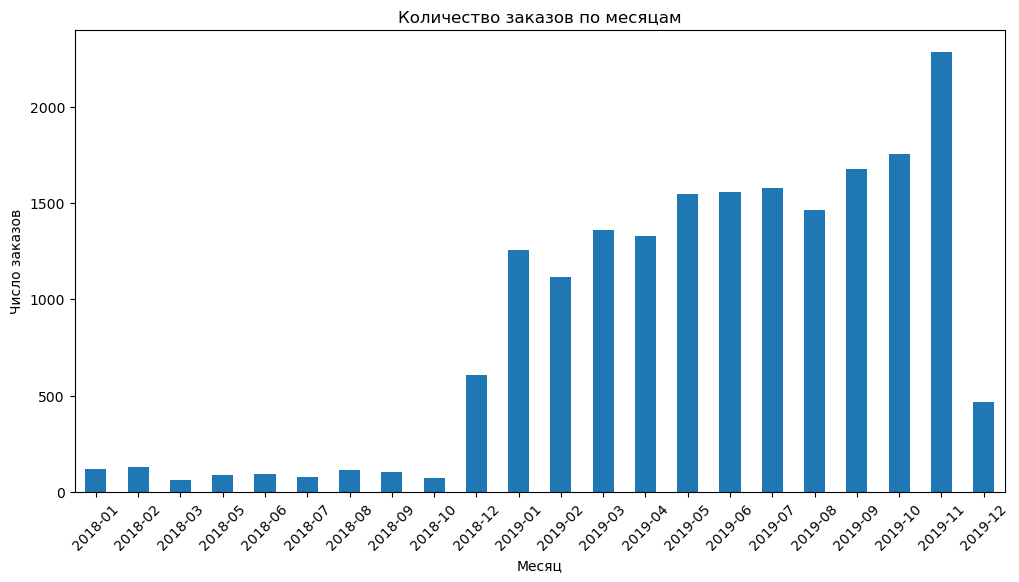

In [56]:
#Посчитаем количество заказов по месяцам и построим график:
df_clean['year_month'] = df_clean['entry_date'].dt.to_period('M')
monthly_orders = df_clean.groupby('year_month')['order_id'].nunique()

plt.figure(figsize=(12,6))
monthly_orders.plot(kind='bar')
plt.title('Количество заказов по месяцам')
plt.ylabel('Число заказов')
plt.xlabel('Месяц')
plt.xticks(rotation=45)
plt.show()

Число заказов росло высокими темпами каждый месяц с декабря 2018 года и достигло пика в ноябре 2019.
Посмотрим, сколько дней в каждом месяце не было продаж. Для этого создадим календарь всех дней в диапазоне и сравним с днями, когда были заказы.

In [59]:
# Полный календарь от min до max
all_dates = pd.date_range(start=df_clean['entry_date'].min(), end=df_clean['entry_date'].max(), freq='D')
# Дни с продажами
daily_orders = df_clean.groupby(df_clean['entry_date'].dt.date)['order_id'].nunique()
# Преобразуем в множества для быстрой проверки
all_dates_set = set(all_dates.date)
daily_dates_set = set(daily_orders.index)
missing_days = all_dates_set - daily_dates_set

print(f"Всего дней в периоде: {len(all_dates)}")
print(f"Дней с продажами: {len(daily_orders)}")
print(f"Дней без продаж: {len(missing_days)}")
print(f"Доля дней без продаж: {len(missing_days) / len(all_dates) * 100:.2f}%")

Всего дней в периоде: 698
Дней с продажами: 305
Дней без продаж: 393
Доля дней без продаж: 56.30%


Такая высокая доля дней без продаж может означать, что магазин работает не ежедневно (например, только по определённым дням недели или сезонно), либо данные поступают с перерывами. Это важно учитывать при расчёте средних дневных показателей (выручка, количество заказов). Если мы хотим оценить среднюю активность в день, то логичнее считать только по дням с продажами, либо использовать медиану. В дальнейшем, при анализе временных рядов, мы можем сгладить эти пропуски или интерполировать, но для начального исследовательского анализа просто отметим этот факт. Дни без продаж не являются аномалией, а скорее особенностью бизнеса.

# Шаг 3. Расчёт метрик

На этом этапе переходим от общей очистки данных к расчёту показателей покупательской активности и клиентского поведения.

Для корректности расчётов сначала создадим представление данных на уровне заказа. Исходный `df_clean` содержит отдельные товарные строки: один `order_id` может встречаться много раз. Поэтому простой подсчёт строк не равен количеству заказов.

Кроме того, в расчётах, связанных с клиентами, исключим `customer_id = -1`. Это специальный идентификатор анонимных покупателей, а не отдельный реальный клиент. Анонимные заказы остаются в расчётах заказов и общей выручки, но не используются для клиентских метрик.


In [ ]:
# 0. Подготовка единого датафрейма на уровне заказа

# Контроль: в одном заказе не должно быть нескольких customer_id.
customer_per_order = df_clean.groupby('order_id')['customer_id'].nunique()
assert customer_per_order.max() == 1, "Встречены заказы с несколькими customer_id."

# Одно наблюдение в df_orders_level = один заказ.
df_orders_level = (
    df_clean.sort_values('entry_date')
    .groupby('order_id', as_index=False)
    .agg(
        order_date=('entry_date', 'min'),
        customer_id=('customer_id', 'first'),
        order_revenue=('total_price', 'sum'),
        items=('quantity', 'sum'),
        country_id=('country_id', 'first')
    )
)

# Производные временные признаки.
df_orders_level['date'] = df_orders_level['order_date'].dt.normalize()
df_orders_level['hour'] = df_orders_level['order_date'].dt.hour
df_orders_level['weekday'] = df_orders_level['order_date'].dt.dayofweek
df_orders_level['year_month'] = df_orders_level['order_date'].dt.to_period('M')
df_orders_level['year'] = df_orders_level['order_date'].dt.year
df_orders_level['quarter'] = df_orders_level['order_date'].dt.quarter

# Для клиентских показателей оставляем только идентифицированных покупателей.
df_known_orders = df_orders_level[df_orders_level['customer_id'] != -1].copy()

print(f"Товарных строк после очистки: {len(df_clean):,}")
print(f"Уникальных заказов: {df_orders_level['order_id'].nunique():,}")
print(f"Заказов идентифицированных клиентов: {len(df_known_orders):,}")
print(f"Уникальных идентифицированных клиентов: {df_known_orders['customer_id'].nunique():,}")


## 3.1. Покупательская активность по часам и дням недели

Сначала оценим, когда покупатели совершают заказы. Показатели рассчитываются на уровне заказа:

- число заказов — количество уникальных `order_id`;
- число покупателей — количество уникальных `customer_id` среди идентифицированных клиентов.

Для часов используем линейные графики: они лучше показывают изменение активности в течение дня и локальные пики. Для дней недели используем столбчатые диаграммы, поскольку это отдельные категориальные значения.


In [ ]:
# 3.1. Активность по часам

orders_by_hour = df_orders_level.groupby('hour')['order_id'].nunique()
customers_by_hour = df_known_orders.groupby('hour')['customer_id'].nunique()

# 3.1. Активность по дням недели
orders_by_weekday = df_orders_level.groupby('weekday')['order_id'].nunique()
customers_by_weekday = df_known_orders.groupby('weekday')['customer_id'].nunique()

weekday_names = [
    'Понедельник', 'Вторник', 'Среда',
    'Четверг', 'Пятница', 'Суббота', 'Воскресенье'
]

# Сводная таблица для контроля результата.
activity_week = pd.DataFrame({
    'Заказы': orders_by_weekday,
    'Уникальные покупатели': customers_by_weekday
}).reindex(range(7))

activity_week.index = weekday_names
display(activity_week)

activity_hour = pd.DataFrame({
    'Заказы': orders_by_hour,
    'Уникальные покупатели': customers_by_hour
})
display(activity_hour)


In [ ]:
# Визуализация: часы и дни недели

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Число заказов по часам
axes[0, 0].plot(
    orders_by_hour.index, orders_by_hour.values,
    marker='o', linewidth=2
)
axes[0, 0].set_title('Количество заказов по часам')
axes[0, 0].set_xlabel('Час')
axes[0, 0].set_ylabel('Уникальные заказы')
axes[0, 0].set_xticks(range(0, 24))
axes[0, 0].grid(axis='y', alpha=0.25)

# Уникальные покупатели по часам
axes[0, 1].plot(
    customers_by_hour.index, customers_by_hour.values,
    marker='o', linewidth=2
)
axes[0, 1].set_title('Уникальные покупатели по часам')
axes[0, 1].set_xlabel('Час')
axes[0, 1].set_ylabel('Уникальные покупатели')
axes[0, 1].set_xticks(range(0, 24))
axes[0, 1].grid(axis='y', alpha=0.25)

# Заказы по дням недели
axes[1, 0].bar(weekday_names, orders_by_weekday.reindex(range(7)).values)
axes[1, 0].set_title('Количество заказов по дням недели')
axes[1, 0].set_xlabel('День недели')
axes[1, 0].set_ylabel('Уникальные заказы')
axes[1, 0].tick_params(axis='x', rotation=35)
axes[1, 0].grid(axis='y', alpha=0.25)

# Покупатели по дням недели
axes[1, 1].bar(weekday_names, customers_by_weekday.reindex(range(7)).values)
axes[1, 1].set_title('Уникальные покупатели по дням недели')
axes[1, 1].set_xlabel('День недели')
axes[1, 1].set_ylabel('Уникальные покупатели')
axes[1, 1].tick_params(axis='x', rotation=35)
axes[1, 1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


### Вывод по активности

Покупательская активность имеет выраженную внутридневную и недельную цикличность.

В течение дня максимум заказов приходится на **12:00 — 3 052 заказа**, а максимум уникальных идентифицированных покупателей также приходится на **12:00 — 1 593 человека**. После полудня активность снижается; вечером и особенно после 19:00 количество заказов становится очень небольшим.

По дням недели максимум приходится на **воскресенье — 3 520 заказов и 1 832 уникальных покупателя**. Минимальная активность наблюдается во вторник — 1 103 заказа и 741 покупатель. Таким образом, воскресенье почти в 3,2 раза превосходит вторник по количеству заказов. Это достаточно сильное различие, чтобы говорить о наличии недельного ритма.

Следовательно, активность магазина нельзя считать равномерной во времени. Наиболее интенсивный период — дневные часы, особенно около полудня, а наиболее активный день — воскресенье. Для бизнес-планирования это может использоваться при распределении рекламной активности, нагрузки на обработку заказов и коммуникаций с клиентами.

Важно, что различие между количеством строк исходного `df_clean` и числом заказов специально устранено агрегацией по `order_id`. В противном случае заказы с большим количеством товарных позиций получили бы завышенный вес.


## 3.2. Средняя выручка с активного клиента в день и число уникальных покупателей по месяцам

Для этого показателя важно заранее определить методику.

Мы используем **среднюю дневную выручку на одного активного идентифицированного клиента**. Сначала для каждого дня рассчитывается:

`дневная выручка / число уникальных клиентов в этот день`

После этого полученные дневные значения усредняются внутри месяца. Такой подход отвечает на вопрос: сколько в среднем приносит один фактически активный клиент за день продаж.

Дополнительно покажем количество уникальных клиентов за месяц и число дней, в которые присутствовали продажи. Последний показатель особенно важен здесь, потому что данные за 2018 год представлены очень неравномерно, а декабрь 2019 года является неполным.


In [ ]:
# 3.2. Дневные и месячные показатели

daily_customer_metrics = (
    df_known_orders
    .groupby('date')
    .agg(
        daily_revenue=('order_revenue', 'sum'),
        daily_unique_customers=('customer_id', 'nunique'),
        daily_orders=('order_id', 'nunique')
    )
    .reset_index()
)

daily_customer_metrics['revenue_per_active_customer'] = (
    daily_customer_metrics['daily_revenue']
    / daily_customer_metrics['daily_unique_customers']
)
daily_customer_metrics['year_month'] = daily_customer_metrics['date'].dt.to_period('M')

monthly_customers = (
    df_known_orders
    .groupby('year_month')
    .agg(
        monthly_revenue=('order_revenue', 'sum'),
        unique_customers=('customer_id', 'nunique'),
        active_days=('date', 'nunique')
    )
    .reset_index()
)

monthly_daily = (
    daily_customer_metrics
    .groupby('year_month')
    .agg(
        avg_daily_revenue_per_active_customer=('revenue_per_active_customer', 'mean'),
        median_daily_revenue_per_active_customer=('revenue_per_active_customer', 'median'),
        avg_daily_customers=('daily_unique_customers', 'mean')
    )
    .reset_index()
)

monthly_metrics = monthly_customers.merge(
    monthly_daily,
    on='year_month',
    how='left'
)

monthly_metrics['calendar_month'] = monthly_metrics['year_month'].dt.month

display(
    monthly_metrics[
        [
            'year_month',
            'monthly_revenue',
            'unique_customers',
            'active_days',
            'avg_daily_customers',
            'avg_daily_revenue_per_active_customer',
            'median_daily_revenue_per_active_customer'
        ]
    ].style.format({
        'monthly_revenue': '{:,.0f}',
        'unique_customers': '{:,.0f}',
        'active_days': '{:,.0f}',
        'avg_daily_customers': '{:,.1f}',
        'avg_daily_revenue_per_active_customer': '{:,.2f}',
        'median_daily_revenue_per_active_customer': '{:,.2f}'
    })
)


In [ ]:
# Визуализация месячной динамики

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

axes[0].plot(
    monthly_metrics['year_month'].astype(str),
    monthly_metrics['unique_customers'],
    marker='o', linewidth=2
)
axes[0].set_title('Количество уникальных идентифицированных покупателей по месяцам')
axes[0].set_ylabel('Уникальные покупатели')
axes[0].grid(axis='y', alpha=0.25)

axes[1].plot(
    monthly_metrics['year_month'].astype(str),
    monthly_metrics['avg_daily_revenue_per_active_customer'],
    marker='o', linewidth=2
)
axes[1].set_title('Средняя дневная выручка на активного клиента')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Выручка на клиента в день')
axes[1].grid(axis='y', alpha=0.25)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### Вывод по месячной динамике

По числу уникальных покупателей в 2019 году наблюдается выраженный рост: от **850 клиентов в январе** до **1 437 в ноябре**. Это увеличение примерно на 69%.

Однако этот результат нельзя автоматически интерпретировать как сезонность. Для уверенного вывода о сезонном эффекте необходимо наблюдать одинаковые календарные периоды хотя бы несколько раз. В данном наборе данных такая возможность ограничена:

- в январе–октябре 2018 года продажи присутствуют лишь в отдельных днях;
- в декабре 2018 года наблюдения также неполные;
- декабрь 2019 года охватывает только **8 дней**.

Поэтому различия между месяцами 2019 года в значительной степени могут отражать общий рост активности, а не повторяющийся сезонный цикл.

Наиболее заметное отклонение наблюдается в сентябре 2019 года: средняя дневная выручка на активного клиента достигает около **57,4 тыс.**, тогда как в большинстве соседних месяцев она находится примерно в диапазоне 32–36 тыс. Это может быть связано с изменением структуры заказов и долей крупных покупок. В контексте магазина, работающего и с оптовыми клиентами, такое поведение особенно вероятно.

Таким образом, на текущем горизонте корректнее говорить о **росте клиентской активности и отдельных всплесках**, а не о доказанной сезонности.


## 3.3. Stickiness Factor во II и III кварталах 2019 года

Stickiness Factor показывает, насколько часто пользователи возвращаются в сервис. Базовая формула:

`SF = (DAU / MAU) × 100%`

где:

- **DAU (Daily Active Users)** — число уникальных активных клиентов за день;
- **MAU (Monthly Active Users)** — число уникальных клиентов за месяц.

В расчёте ниже используются только идентифицированные клиенты. Для квартального показателя сначала рассчитывается дневная аудитория и месячная аудитория по каждому месяцу квартала, после чего показатели агрегируются как среднее дневное DAU и среднее месячное MAU.

RFM-анализ, который будет использоваться в последующих этапах проекта, также относится к поведенческой клиентской сегментации. В классическом подходе RFM означает **Recency, Frequency, Monetary** — давность покупки, частоту покупок и денежную ценность клиента. citeturn897857search0turn897857search1


In [ ]:
# 3.3. Расчёт DAU, MAU и Stickiness Factor

# День и месяц активности клиента.
df_known_orders['year_month'] = df_known_orders['date'].dt.to_period('M')

daily_active = (
    df_known_orders
    .groupby(['year_month', 'date'])['customer_id']
    .nunique()
    .rename('DAU')
    .reset_index()
)

monthly_active = (
    df_known_orders
    .groupby('year_month')['customer_id']
    .nunique()
    .rename('MAU')
    .reset_index()
)

stickiness_monthly = daily_active.merge(
    monthly_active,
    on='year_month',
    how='left'
)

stickiness_monthly['SF'] = (
    stickiness_monthly['DAU']
    / stickiness_monthly['MAU']
    * 100
)

stickiness_monthly['year'] = stickiness_monthly['year_month'].dt.year
stickiness_monthly['quarter'] = stickiness_monthly['year_month'].dt.quarter

quarterly_stickiness = (
    stickiness_monthly[
        (stickiness_monthly['year'] == 2019)
        & (stickiness_monthly['quarter'].isin([2, 3]))
    ]
    .groupby('quarter')
    .agg(
        avg_DAU=('DAU', 'mean'),
        avg_MAU=('MAU', 'mean'),
        avg_SF=('SF', 'mean'),
        median_DAU=('DAU', 'median'),
        median_SF=('SF', 'median')
    )
    .reset_index()
)

quarterly_stickiness['quarter'] = quarterly_stickiness['quarter'].map({
    2: 'II квартал 2019',
    3: 'III квартал 2019'
})

display(
    quarterly_stickiness.style.format({
        'avg_DAU': '{:,.2f}',
        'avg_MAU': '{:,.2f}',
        'avg_SF': '{:.2f}%',
        'median_DAU': '{:,.0f}',
        'median_SF': '{:.2f}%'
    })
)


In [ ]:
# Визуализация месячного Stickiness Factor

stickiness_plot = (
    stickiness_monthly[
        (stickiness_monthly['year'] == 2019)
        & (stickiness_monthly['quarter'].isin([2, 3]))
    ]
    .groupby('year_month')
    .agg(
        avg_DAU=('DAU', 'mean'),
        MAU=('MAU', 'first'),
        SF=('SF', 'mean')
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    stickiness_plot['year_month'].astype(str),
    stickiness_plot['SF'],
    marker='o', linewidth=2
)
ax.set_title('Stickiness Factor по месяцам, II–III кварталы 2019 года')
ax.set_xlabel('Месяц')
ax.set_ylabel('SF, %')
ax.grid(axis='y', alpha=0.25)
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


### Вывод по Stickiness Factor

Во **II квартале 2019 года** среднее DAU составляет около **51,15 клиента**, среднее MAU — около **954 клиентов**, а Stickiness Factor — **5,36%**.

В **III квартале 2019 года** среднее DAU увеличивается до **52,53 клиента**, а среднее MAU — до **1 047,67 клиента**. При этом SF снижается до **5,01%**.

Это означает, что абсолютная ежедневная активность немного выросла, но месячная база росла быстрее. Иными словами, магазин привлекал больше уникальных клиентов в месяц, но доля месячной аудитории, которая проявляла активность в отдельно взятый день, немного уменьшилась.

Снижение SF с 5,36% до 5,01% составляет около **0,35 процентного пункта**. Это не означает ухудшение продаж само по себе: показатель отражает частоту возвращения клиентов и должен рассматриваться вместе с количеством клиентов, заказов и выручкой.


## 3.4. Профиль каждого клиента

Теперь агрегируем заказы по `customer_id` и получаем единую строку на каждого идентифицированного покупателя.

В профиль включим:

- количество заказов;
- дату первого заказа;
- дату последнего заказа;
- общую сумму покупок;
- средний и медианный чек;
- общее количество приобретённых единиц товара;
- среднее количество единиц товара в заказе;
- число активных дней;
- число стран, из которых клиент совершал заказы;
- длительность отношений с магазином в днях.

Среднее значение дополняем медианой, поскольку в данных уже на предыдущем этапе обнаружено правостороннее распределение и наличие крупных заказов. Для такого распределения одна только средняя величина может давать искажённое представление о типичном клиенте.


In [ ]:
# 3.4. Клиентский профиль

customer_profile = (
    df_known_orders
    .groupby('customer_id')
    .agg(
        orders_count=('order_id', 'nunique'),
        first_order=('order_date', 'min'),
        last_order=('order_date', 'max'),
        total_spend=('order_revenue', 'sum'),
        avg_order_value=('order_revenue', 'mean'),
        median_order_value=('order_revenue', 'median'),
        total_items=('items', 'sum'),
        avg_items_per_order=('items', 'mean'),
        active_days=('date', 'nunique'),
        countries_count=('country_id', 'nunique')
    )
    .reset_index()
)

customer_profile['lifetime_days'] = (
    customer_profile['last_order']
    - customer_profile['first_order']
).dt.days

customer_profile['repeat_customer'] = customer_profile['orders_count'] >= 2

display(
    customer_profile.head(10).style.format({
        'total_spend': '{:,.0f}',
        'avg_order_value': '{:,.0f}',
        'median_order_value': '{:,.0f}',
        'avg_items_per_order': '{:,.1f}'
    })
)

print(f"Всего профилей идентифицированных клиентов: {len(customer_profile):,}")


In [ ]:
# Базовая статистика клиентских профилей

profile_statistics = customer_profile[
    [
        'orders_count',
        'total_spend',
        'avg_order_value',
        'median_order_value',
        'total_items',
        'avg_items_per_order',
        'active_days',
        'lifetime_days'
    ]
].describe().T

display(profile_statistics.style.format({
    'count': '{:,.0f}',
    'mean': '{:,.2f}',
    'std': '{:,.2f}',
    'min': '{:,.2f}',
    '25%': '{:,.2f}',
    '50%': '{:,.2f}',
    '75%': '{:,.2f}',
    'max': '{:,.2f}'
}))


In [ ]:
# Визуализация распределения числа заказов и общей суммы покупок

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Количество заказов: логарифмическая шкала по X помогает увидеть основной массив.
axes[0].hist(customer_profile['orders_count'], bins=30)
axes[0].set_title('Распределение числа заказов на клиента')
axes[0].set_xlabel('Количество заказов')
axes[0].set_ylabel('Число клиентов')
axes[0].grid(axis='y', alpha=0.25)

# Общая сумма покупок сильно асимметрична — используем логарифмическую шкалу.
axes[1].hist(customer_profile['total_spend'], bins=40)
axes[1].set_title('Распределение общей суммы покупок')
axes[1].set_xlabel('Общая сумма покупок')
axes[1].set_ylabel('Число клиентов')
axes[1].set_xscale('log')
axes[1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


### Вывод по профилям клиентов

После исключения анонимных записей получено **4 247 клиентских профилей**.

Распределение частоты покупок сильно несимметрично: медианный клиент оформляет **2 заказа**, тогда как среднее число заказов равно примерно **4,13**. Максимальное значение достигает **198 заказов на одного клиента**. Это подтверждает необходимость использовать медианные показатели вместе со средними.

Профиль клиента позволяет перейти от анализа отдельных транзакций к анализу жизненного цикла покупателя. Особенно важными для последующей сегментации будут `orders_count`, `total_spend`, `last_order` и `first_order`: они непосредственно соответствуют логике поведенческого анализа клиентов и станут основой для RFM-сегментации.


## 3.5. Возвратные и одноразовые клиенты

Клиента считаем **возвратным**, если он совершил не менее двух заказов за весь наблюдаемый период.

Это определение основано непосредственно на наличии повторной покупки и не требует произвольного временного порога. Далее сравним группы по размеру клиентской базы, частоте заказов, общей сумме покупок, среднему чеку, количеству товаров и длительности взаимодействия с магазином.


In [ ]:
# 3.5. Формирование двух групп

customer_profile['customer_type'] = np.where(
    customer_profile['orders_count'] >= 2,
    'Возвратный',
    'Одноразовый'
)

group_summary = (
    customer_profile
    .groupby('customer_type')
    .agg(
        customers=('customer_id', 'count'),
        avg_orders=('orders_count', 'mean'),
        median_orders=('orders_count', 'median'),
        avg_total_spend=('total_spend', 'mean'),
        median_total_spend=('total_spend', 'median'),
        avg_order_value=('avg_order_value', 'mean'),
        median_order_value=('avg_order_value', 'median'),
        avg_total_items=('total_items', 'mean'),
        avg_items_per_order=('avg_items_per_order', 'mean'),
        avg_active_days=('active_days', 'mean'),
        avg_lifetime_days=('lifetime_days', 'mean')
    )
    .reset_index()
)

# Доля каждой группы.
group_summary['customer_share'] = (
    group_summary['customers']
    / group_summary['customers'].sum()
    * 100
)

display(
    group_summary.style.format({
        'customers': '{:,.0f}',
        'customer_share': '{:.2f}%',
        'avg_orders': '{:,.2f}',
        'median_orders': '{:,.1f}',
        'avg_total_spend': '{:,.0f}',
        'median_total_spend': '{:,.0f}',
        'avg_order_value': '{:,.0f}',
        'median_order_value': '{:,.0f}',
        'avg_total_items': '{:,.1f}',
        'avg_items_per_order': '{:,.1f}',
        'avg_active_days': '{:,.2f}',
        'avg_lifetime_days': '{:,.1f}'
    })
)


In [ ]:
# Сравнение групп: средние значения ключевых денежных и поведенческих метрик

comparison_metrics = pd.DataFrame({
    'Метрика': [
        'Среднее число заказов',
        'Средняя общая сумма покупок',
        'Медианная общая сумма покупок',
        'Средний чек',
        'Медианный чек',
        'Среднее количество товаров',
        'Среднее число активных дней'
    ],
    'Возвратные': [
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'orders_count'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'total_spend'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'total_spend'].median(),
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'avg_order_value'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'avg_order_value'].median(),
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'total_items'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Возвратный', 'active_days'].mean()
    ],
    'Одноразовые': [
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'orders_count'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'total_spend'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'total_spend'].median(),
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'avg_order_value'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'avg_order_value'].median(),
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'total_items'].mean(),
        customer_profile.loc[customer_profile['customer_type']=='Одноразовый', 'active_days'].mean()
    ]
})

comparison_metrics['Разница, %'] = (
    (comparison_metrics['Возвратные'] / comparison_metrics['Одноразовые'] - 1)
    * 100
)

display(
    comparison_metrics.style.format({
        'Возвратные': '{:,.2f}',
        'Одноразовые': '{:,.2f}',
        'Разница, %': '{:+.1f}%'
    })
)


In [ ]:
# Визуализация различий между возвратными и одноразовыми клиентами

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Размер групп
group_counts = customer_profile['customer_type'].value_counts().reindex(
    ['Одноразовый', 'Возвратный']
)
axes[0].bar(group_counts.index, group_counts.values)
axes[0].set_title('Размер клиентских групп')
axes[0].set_ylabel('Количество клиентов')
axes[0].grid(axis='y', alpha=0.25)

# Средняя сумма покупок
mean_spend = customer_profile.groupby('customer_type')['total_spend'].mean().reindex(
    ['Одноразовый', 'Возвратный']
)
axes[1].bar(mean_spend.index, mean_spend.values)
axes[1].set_title('Средняя общая сумма покупок')
axes[1].set_ylabel('Сумма')
axes[1].grid(axis='y', alpha=0.25)

# Средний чек
mean_aov = customer_profile.groupby('customer_type')['avg_order_value'].mean().reindex(
    ['Одноразовый', 'Возвратный']
)
axes[2].bar(mean_aov.index, mean_aov.values)
axes[2].set_title('Средний чек')
axes[2].set_ylabel('Сумма')
axes[2].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()


### Итоговый вывод по возвратным и одноразовым клиентам

Из 4 247 идентифицированных клиентов **2 761 (65,0%) являются возвратными**, а **1 486 (35,0%) — одноразовыми**.

Разница между группами существенна:

- возвратный клиент в среднем совершает **5,81 заказа**, тогда как одноразовый — ровно 1;
- средняя общая сумма покупок возвратного клиента составляет около **191,0 тыс.**, против **24,3 тыс.** у одноразового;
- средний чек возвратного клиента — около **29,5 тыс.**, у одноразового — **24,3 тыс.**;
- возвратные клиенты приобретают существенно больше товаров и активны в среднем примерно **5,3 дня**, тогда как одноразовые — только в один день.

Особенно важно различать **общую ценность клиента** и **размер отдельного заказа**. Основной вклад возвратных покупателей в денежную ценность возникает не только из-за немного более высокого среднего чека, но прежде всего из-за повторных заказов. Средняя сумма всех покупок возвратного клиента примерно в **7,9 раза выше**, чем у одноразового.

Поэтому для бизнеса ключевой задачей является не только привлечение новых покупателей, но и перевод одноразовых клиентов в повторные. Полученный клиентский профиль станет базой для следующего этапа — более детальной сегментации, в том числе RFM, где клиенты будут сравниваться по давности последней покупки, частоте заказов и денежной ценности. RFM-подход используется именно для поведенческого ранжирования и сегментации клиентов по этим трём измерениям. citeturn897857search0turn897857search4


## Источники и методические материалы

1. Hanna, K. T., & Wright, G. (2024, March 29). *What is RFM analysis (recency, frequency, monetary)?* TechTarget. https://www.techtarget.com/data-technologies/definition/RFM-analysis-recency-frequency-monetary

2. Microsoft. (2026). *Set up Recency, Frequency, and Monetary (RFM) analysis*. Microsoft Learn. https://learn.microsoft.com/en-us/dynamics365/commerce/set-up-rfm-analysis

**Источник исходных данных:** `gift.csv` и `gift_entry.csv`, предоставленные для выполнения проекта.


# Шаг 4. RFM-сегментация клиентов

RFM-анализ позволяет разделить клиентов по трём характеристикам покупательского поведения: **Recency** — давность последней покупки, **Frequency** — частота покупок и **Monetary** — денежная ценность клиента. Такой подход используется для поведенческой сегментации клиентской базы и последующего выбора разных сценариев взаимодействия с клиентами. В классическом варианте каждому показателю присваивается балл: чем выше итоговый балл, тем благоприятнее профиль клиента для бизнеса.

В нашем проекте сохраняем шкалу из задания **от 1 до 3**. Расчёт строится непосредственно на клиентских профилях из шага 3: `last_order`, `orders_count` и `total_spend`. Анонимные записи уже исключены на предыдущем шаге, поэтому в RFM участвуют только идентифицированные клиенты.

Для Recency и Monetary используем разбиение на три группы по терцилям. Для Frequency применяем ту же логику, что дана в примере задания: 1 заказ = низкая частота, 2–3 заказа = средняя, 4 и более = высокая.


In [ ]:
# 4.1. Расчёт показателей RFM и присвоение баллов

# Дата анализа — следующий календарный день после последней покупки в данных.
# Это стандартный способ избежать нулевой recency для клиента, купившего в последний день наблюдения.
analysis_date = customer_profile['last_order'].max().normalize() + pd.Timedelta(days=1)

rfm = customer_profile[[
    'customer_id', 'first_order', 'last_order', 'orders_count', 'total_spend',
    'avg_order_value', 'total_items', 'active_days', 'lifetime_days'
]].copy()

# R — количество дней с последней покупки. Чем меньше значение, тем выше балл.
rfm['recency'] = (analysis_date - rfm['last_order'].dt.normalize()).dt.days

# F — количество уникальных заказов клиента за весь период наблюдения.
rfm['frequency'] = rfm['orders_count']

# M — общая сумма покупок клиента за весь период наблюдения.
rfm['monetary'] = rfm['total_spend']

# Балл Recency: самые свежие покупки получают 3, самые давние — 1.
rfm['r_score'] = pd.qcut(
    rfm['recency'], q=3, labels=[3, 2, 1]
).astype(int)

# Балл Frequency: 1 заказ = 1; 2–3 заказа = 2; 4+ заказов = 3.
rfm['f_score'] = pd.cut(
    rfm['frequency'],
    bins=[0, 1, 3, rfm['frequency'].max() + 1],
    labels=[1, 2, 3],
    include_lowest=True,
    right=False
).astype(int)

# Балл Monetary: клиенты с наибольшими тратами получают 3.
rfm['m_score'] = pd.qcut(
    rfm['monetary'], q=3, labels=[1, 2, 3]
).astype(int)

# Итоговый RFM-код и сумма баллов.
rfm['rfm_group'] = (
    rfm['r_score'].astype(str)
    + rfm['f_score'].astype(str)
    + rfm['m_score'].astype(str)
)
rfm['rfm_sum'] = rfm[['r_score', 'f_score', 'm_score']].sum(axis=1)

print(f'Дата анализа: {analysis_date.date()}')
print(f'Клиентов в RFM-анализе: {rfm["customer_id"].nunique():,}')
print('Диапазон Recency:', rfm['recency'].min(), '—', rfm['recency'].max(), 'дней')
print('Диапазон Frequency:', rfm['frequency'].min(), '—', rfm['frequency'].max(), 'заказов')
print('Диапазон Monetary:', f'{rfm["monetary"].min():,.0f}', '—', f'{rfm["monetary"].max():,.0f}')

display(rfm.head(10).style.format({
    'monetary': '{:,.0f}',
    'avg_order_value': '{:,.0f}',
    'total_items': '{:,.0f}',
    'lifetime_days': '{:,.0f}'
}))


### Как интерпретировать баллы

Для всех трёх показателей высокий балл означает более привлекательное поведение клиента. Поэтому код `333` соответствует клиенту, который покупал недавно, делает покупки часто и имеет высокую денежную ценность. Код `111`, напротив, характеризует клиента с давней последней покупкой, единственным или очень редким заказом и низкими суммарными расходами.

Важно, что RFM-балл не является абсолютной оценкой клиента: он показывает положение покупателя **относительно других клиентов этой же базы**. Поэтому сегменты следует использовать прежде всего для сравнения и выбора различных сценариев коммуникации.


In [ ]:
# 4.2. Сводная таблица RFM-сегментов

rfm_group = (
    rfm
    .groupby('rfm_group', as_index=False)
    .agg(
        customers=('customer_id', 'nunique'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        total_revenue=('monetary', 'sum'),
        rfm_sum=('rfm_sum', 'first')
    )
    .sort_values(['customers', 'rfm_group'], ascending=[False, True])
)

rfm_group['customer_share'] = (
    rfm_group['customers'] / rfm['customer_id'].nunique() * 100
)
rfm_group['revenue_share'] = (
    rfm_group['total_revenue'] / rfm['monetary'].sum() * 100
)

# Проверяем, какие из 27 теоретически возможных комбинаций реально представлены.
all_rfm_codes = {
    f'{r}{f}{m}'
    for r in [1, 2, 3]
    for f in [1, 2, 3]
    for m in [1, 2, 3]
}
observed_rfm_codes = set(rfm_group['rfm_group'])
empty_rfm_codes = sorted(all_rfm_codes - observed_rfm_codes)
print(f'Заполнено RFM-комбинаций: {len(observed_rfm_codes)} из 27')
print('Незаполненные комбинации:', ', '.join(empty_rfm_codes) if empty_rfm_codes else 'нет')

display(
    rfm_group.style.format({
        'customers': '{:,.0f}',
        'customer_share': '{:.2f}%',
        'avg_recency': '{:,.1f}',
        'avg_frequency': '{:,.2f}',
        'avg_monetary': '{:,.0f}',
        'total_revenue': '{:,.0f}',
        'revenue_share': '{:.2f}%',
        'rfm_sum': '{:,.0f}'
    })
)


In [ ]:
# 4.3. Тепловая карта размера сегментов по Recency и Frequency

rfm_matrix = rfm.pivot_table(
    index='r_score',
    columns='f_score',
    values='customer_id',
    aggfunc='nunique',
    fill_value=0
).reindex(index=[3, 2, 1], columns=[1, 2, 3])

plt.figure(figsize=(8, 6))
sns.heatmap(
    rfm_matrix,
    annot=True,
    fmt='.0f',
    cmap='Blues',
    linewidths=0.5,
    cbar_kws={'label': 'Количество клиентов'}
)
plt.title('RFM: количество клиентов по Recency и Frequency')
plt.xlabel('Баллы Frequency')
plt.ylabel('Баллы Recency')
plt.tight_layout()
plt.show()

display(rfm_matrix)


In [ ]:
# 4.4. Treemap всех RFM-сегментов

import plotly.express as px

fig = px.treemap(
    rfm_group,
    path=['rfm_group'],
    values='customers',
    color='rfm_sum',
    color_continuous_scale='Sunset',
    hover_data={
        'customers': ':,',
        'customer_share': ':.2f',
        'avg_recency': ':.1f',
        'avg_frequency': ':.2f',
        'avg_monetary': ':,.0f',
        'total_revenue': ':,.0f',
        'revenue_share': ':.2f',
        'rfm_sum': True
    },
    title='RFM-сегментация клиентов интернет-магазина'
)
fig.update_layout(
    margin=dict(t=60, l=10, r=10, b=10),
    coloraxis_colorbar_title='Сумма RFM'
)
fig.show()


## Оценка получившихся групп

В RFM-модели существует **27 теоретически возможных комбинаций**: от `111` до `333`. В нашем наборе данных представлены все 27 комбинаций, поэтому каждый вариант сочетания давности, частоты и денежной ценности имеет хотя бы одного клиента.

Наиболее крупные сегменты — **`333`**, **`111`** и **`233`**. Сегмент `333` объединяет клиентов с максимальными баллами по всем трём характеристикам: они недавно совершали покупки, делают их часто и относятся к верхней трети по сумме расходов. Напротив, `111` соответствует клиентам с наиболее слабым сочетанием всех трёх показателей. Сегмент `233` особенно интересен: эти клиенты обладают высокой частотой и денежной ценностью, но их последняя покупка была не такой свежей, как у группы `333`.

Это показывает, почему нельзя ориентироваться только на сумму баллов. Например, два сегмента могут иметь одинаковый общий RFM-балл, но различаться по структуре: у одного клиента высокий Frequency, у другого — высокий Monetary. Бизнес-задача в этих случаях будет различной. Поэтому далее используем одновременно конкретный RFM-код и укрупнённые бизнес-сегменты.


In [ ]:
# 4.5. Укрупнение RFM-сегментов для бизнес-интерпретации
# 27 кодов удобно дополнительно объединить в несколько понятных групп для рекомендаций.

def define_rfm_segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']

    if r == 3 and f == 3 and m == 3:
        return 'Чемпионы'
    elif r >= 2 and f >= 2 and m >= 2:
        return 'Лояльные'
    elif r == 3 and f == 1:
        return 'Новые / перспективные'
    elif r <= 1 and f >= 2 and m == 3:
        return 'Ценные под риском'
    elif r <= 1 and f >= 2:
        return 'Под риском'
    elif r == 1 and f == 1:
        return 'Неактивные'
    else:
        return 'Требуют внимания'

rfm['segment'] = rfm.apply(define_rfm_segment, axis=1)

segment_summary = (
    rfm
    .groupby('segment', as_index=False)
    .agg(
        customers=('customer_id', 'nunique'),
        avg_recency=('recency', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        total_revenue=('monetary', 'sum')
    )
)

segment_summary['customer_share'] = (
    segment_summary['customers'] / len(rfm) * 100
)
segment_summary['revenue_share'] = (
    segment_summary['total_revenue'] / rfm['monetary'].sum() * 100
)

segment_summary = segment_summary.sort_values('customers', ascending=False)

display(segment_summary.style.format({
    'customers': '{:,.0f}',
    'customer_share': '{:.2f}%',
    'avg_recency': '{:,.1f}',
    'avg_frequency': '{:,.2f}',
    'avg_monetary': '{:,.0f}',
    'total_revenue': '{:,.0f}',
    'revenue_share': '{:.2f}%'
}))


In [ ]:
# 4.6. Визуализация укрупнённых сегментов

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

segment_plot = segment_summary.sort_values('customers', ascending=True)

axes[0].barh(segment_plot['segment'], segment_plot['customers'])
axes[0].set_title('Размер укрупнённых RFM-сегментов')
axes[0].set_xlabel('Количество клиентов')
axes[0].grid(axis='x', alpha=0.25)

revenue_plot = segment_summary.sort_values('total_revenue', ascending=True)
axes[1].barh(revenue_plot['segment'], revenue_plot['total_revenue'])
axes[1].set_title('Суммарная выручка по укрупнённым RFM-сегментам')
axes[1].set_xlabel('Выручка')
axes[1].grid(axis='x', alpha=0.25)

plt.tight_layout()
plt.show()


## Рекомендации по работе с сегментами

| Сегмент | Характеристика | Основная задача бизнеса | Рекомендуемое действие |
|---|---|---|---|
| **Чемпионы** | Недавно покупают, часто покупают и много тратят | Сохранить текущую ценность | Персональные предложения, ранний доступ к новинкам, программа лояльности, cross-sell |
| **Лояльные** | Хорошая частота и денежная ценность при достаточно свежей активности | Развивать долгосрочную ценность | Персонализация ассортимента, наборы товаров, стимулирование следующего заказа |
| **Новые / перспективные** | Недавняя покупка, но пока только низкая частота | Получить вторую покупку | Welcome-коммуникации, рекомендации сопутствующих товаров, предложение на повторный заказ |
| **Ценные под риском** | Раньше покупали часто и/или много, но давно не возвращались | Вернуть наиболее ценных клиентов | Персональная win-back-коммуникация, индивидуальное предложение, напоминание о релевантных товарах |
| **Под риском** | Есть история повторных покупок, но клиент давно не активен | Предотвратить отток | Реактивационные кампании с умеренными затратами |
| **Неактивные** | Давно не покупают, частота низкая, денежная ценность ниже | Проверить экономическую целесообразность возврата | Использовать недорогие массовые коммуникации; избегать дорогих персональных стимулов без реакции |
| **Требуют внимания** | Промежуточное сочетание R, F и M | Определить конкретную причину и потенциал | Работать по конкретному RFM-коду, а не по одной общей акции |

По данным сегментации наибольшую практическую ценность имеют две группы. **«Чемпионы»** — источник основной текущей выручки, поэтому для них важнее удержание, чем агрессивное стимулирование. **«Ценные под риском»** значительно меньше по численности, но их историческая денежная ценность выше средней, поэтому их стоит выделить в отдельный приоритетный win-back-сценарий. Для **«Новых / перспективных»** ключевая цель — перевод первой покупки во вторую. Для **«Неактивных»** стоимость возврата должна быть ниже ожидаемой ценности клиента.


## Итоговый вывод по шагу 4

RFM-сегментация показала существенную неоднородность клиентской базы. Наиболее ценный профиль — `333`: клиент недавно покупал, часто покупает и имеет высокий объём расходов. На противоположной стороне находится `111`, где все три характеристики находятся на низком уровне. Между ними существует широкий набор промежуточных комбинаций, поэтому единая маркетинговая стратегия для всей базы была бы неэффективной.

По укрупнённым группам **«Чемпионы» составляют 16,5% клиентской базы, но формируют около 55,5% её выручки**. Это ключевая группа для удержания. **«Лояльные»** составляют около 30,8% клиентов и дают около 30,7% выручки, поэтому это основной резерв для дальнейшего развития ценности. **«Ценные под риском»** — только около 3,0% клиентов, но на них приходится примерно 4,0% выручки; их стоит рассматривать отдельно от обычного сегмента риска.

Таким образом, RFM помогает перейти от общей характеристики клиентской базы к адресным действиям: удерживать самых ценных клиентов, возвращать ценных покупателей с высокой давностью, стимулировать первые повторные покупки и не тратить одинаковый маркетинговый бюджет на клиентов с принципиально разной ценностью.

### Источники по методике RFM

CleverTap. (2026). *RFM Analysis*. https://docs.clevertap.com/docs/rfm

IBM. (2026). *Direct Marketing*. https://www.ibm.com/products/spss-statistics/direct-marketing


# Шаг 5. Проверка статистических гипотез

На этом этапе проверим три исследовательских вопроса с помощью статистических методов. Важно не только получить p-value, но и выбрать тест с учётом структуры данных и сформулировать вывод, понятный бизнес-заказчику.

В расчётах используются данные на уровне заказа `df_orders_level` и только идентифицированные покупатели `df_known_orders`, созданные на предыдущих этапах проекта. Такой подход позволяет не считать отдельные товарные строки самостоятельными заказами.

Будем использовать уровень статистической значимости **α = 0,05**. Для проверки различий долей применим двухвыборочный z-тест пропорций. Для сравнения средних чеков по странам сначала проверим форму распределения и равенство дисперсий, после чего используем Welch ANOVA и парные Welch t-тесты с поправкой Холма; в качестве устойчивой дополнительной проверки применим критерий Краскела–Уоллиса. Для собственной гипотезы сравним средние чеки в будни и выходные с помощью Welch t-теста и дополнительно Mann–Whitney U.

In [ ]:
# Импортируем статистические инструменты.
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05

print(f'Уровень значимости: α = {ALPHA}')
print(f'Идентифицированных заказов: {len(df_known_orders):,}')
print(f'Идентифицированных клиентов: {df_known_orders["customer_id"].nunique():,}')

## 5.1. Сравнение долей возвратных клиентов во II и III кварталах 2019 года

Для каждого квартала определим возвратного клиента как покупателя, совершившего **не менее двух уникальных заказов внутри рассматриваемого квартала**. Тогда доля возвратных клиентов показывает, какая часть активной в квартале аудитории совершила повторную покупку в течение того же квартала.

**Нулевая гипотеза H₀:** доля возвратных клиентов во II и III кварталах одинакова.

**Альтернативная гипотеза H₁:** доли возвратных клиентов различаются.

Для сравнения используем двухвыборочный z-тест пропорций. Поскольку один и тот же покупатель может присутствовать в обоих кварталах, выборки не полностью независимы; поэтому результат трактуем как сравнение наблюдаемых квартальных долей, а не как независимое сравнение двух групп клиентов.

In [ ]:
# Формируем квартальные профили клиентов: сколько заказов сделал каждый клиент внутри квартала.
q_orders = (
    df_known_orders[
        (df_known_orders['year'] == 2019) &
        (df_known_orders['quarter'].isin([2, 3]))
    ]
    .groupby(['quarter', 'customer_id'])['order_id']
    .nunique()
    .rename('orders_in_quarter')
    .reset_index()
)

quarter_return = (
    q_orders
    .groupby('quarter')
    .agg(
        active_customers=('customer_id', 'nunique'),
        returning_customers=('orders_in_quarter', lambda x: (x >= 2).sum())
    )
    .reset_index()
)

quarter_return['nonreturning_customers'] = (
    quarter_return['active_customers'] - quarter_return['returning_customers']
)
quarter_return['return_rate'] = (
    quarter_return['returning_customers'] / quarter_return['active_customers']
)
quarter_return['nonreturn_rate'] = (
    quarter_return['nonreturning_customers'] / quarter_return['active_customers']
)
quarter_return['quarter_name'] = quarter_return['quarter'].map({
    2: 'II квартал 2019',
    3: 'III квартал 2019'
})

# Двухвыборочный z-тест для долей возвратных клиентов.
counts = quarter_return['returning_customers'].to_numpy()
observations = quarter_return['active_customers'].to_numpy()

z_stat, p_value = proportions_ztest(
    count=counts,
    nobs=observations,
    alternative='two-sided'
)

# 95%-ные доверительные интервалы для отдельных долей.
quarter_return['ci_low'] = np.nan
quarter_return['ci_high'] = np.nan
for idx, row in quarter_return.iterrows():
    p_hat = row['return_rate']
    n = row['active_customers']
    se = np.sqrt(p_hat * (1 - p_hat) / n)
    quarter_return.loc[idx, 'ci_low'] = p_hat - 1.96 * se
    quarter_return.loc[idx, 'ci_high'] = p_hat + 1.96 * se

quarter_return['return_rate_pct'] = quarter_return['return_rate'] * 100
quarter_return['ci_low_pct'] = quarter_return['ci_low'] * 100
quarter_return['ci_high_pct'] = quarter_return['ci_high'] * 100

print(f'z = {z_stat:.3f}')
print(f'p-value = {p_value:.4f}')

display(
    quarter_return[
        ['quarter_name', 'active_customers', 'returning_customers',
         'nonreturning_customers', 'return_rate_pct', 'ci_low_pct', 'ci_high_pct']
    ].style.format({
        'active_customers': '{:,.0f}',
        'returning_customers': '{:,.0f}',
        'nonreturning_customers': '{:,.0f}',
        'return_rate_pct': '{:.2f}%',
        'ci_low_pct': '{:.2f}%',
        'ci_high_pct': '{:.2f}%'
    })
)

In [ ]:
# Визуализируем доли возвратных и одноразовых клиентов.
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(quarter_return))
width = 0.36

ax.bar(
    x - width / 2,
    quarter_return['returning_customers'],
    width,
    label='Возвратные'
)
ax.bar(
    x + width / 2,
    quarter_return['nonreturning_customers'],
    width,
    label='Одноразовые'
)

ax.set_xticks(x)
ax.set_xticklabels(quarter_return['quarter_name'])
ax.set_ylabel('Количество клиентов')
ax.set_title('Возвратные и одноразовые клиенты во II и III кварталах 2019 года')
ax.legend()
ax.grid(axis='y', alpha=0.25)

for i, row in quarter_return.iterrows():
    ax.text(
        i - width / 2,
        row['returning_customers'] + 20,
        f"{row['return_rate_pct']:.1f}%",
        ha='center'
    )

plt.tight_layout()
plt.show()

### Вывод по сравнению долей

Во II квартале 2019 года доля возвратных клиентов составляет **42,04%**, а в III квартале — **43,26%**. Разница равна примерно **1,22 процентного пункта**.

Полученное значение `p-value` существенно выше 0,05, поэтому **нулевая гипотеза не отвергается**. На имеющихся данных нет статистически значимых оснований утверждать, что доля возвратных клиентов изменилась между II и III кварталами 2019 года.

Для бизнеса это означает, что рост клиентской базы в III квартале сам по себе не сопровождался подтверждённым изменением доли покупателей, совершавших повторную покупку внутри квартала.

## 5.2. Сравнение средних чеков в странах country_id = 3, 6 и 24

Для сравнения используем **чек одного заказа** — `order_revenue`. Это важно: исходный файл хранит товарные строки, поэтому сравнивать сумму строк напрямую было бы некорректно.

Проверим:

**H₀:** средние чеки во всех трёх странах одинаковы.

**H₁:** хотя бы в одной стране средний чек отличается.

Сначала оценим распределения. В предыдущих шагах уже была выявлена сильная асимметрия денежных показателей, поэтому дополнительно посмотрим на нормальность и равенство дисперсий. Если дисперсии различаются, вместо классического ANOVA используем **Welch ANOVA**, менее чувствительный к неоднородности дисперсий.

In [ ]:
# Выбираем заказы идентифицированных покупателей из трёх стран.
country_aov = df_known_orders[
    df_known_orders['country_id'].isin([3, 6, 24])
].copy()

country_order_stats = (
    country_aov
    .groupby('country_id')['order_revenue']
    .agg(['count', 'mean', 'median', 'std'])
    .reset_index()
)

display(
    country_order_stats.style.format({
        'count': '{:,.0f}',
        'mean': '{:,.2f}',
        'median': '{:,.2f}',
        'std': '{:,.2f}'
    })
)

country_samples = [
    country_aov.loc[country_aov['country_id'] == country, 'order_revenue'].to_numpy()
    for country in [3, 6, 24]
]

# Shapiro–Wilk применяем к случайным подвыборкам одинакового размера,
# чтобы тест не был чрезмерно чувствителен к огромному числу наблюдений.
for country in [3, 6, 24]:
    sample = country_aov.loc[
        country_aov['country_id'] == country, 'order_revenue'
    ]
    sample = sample.sample(min(5000, len(sample)), random_state=42)
    shapiro_p = stats.shapiro(sample).pvalue
    print(f'country_id={country}: Shapiro-Wilk p-value = {shapiro_p:.6g}')

# Проверяем равенство дисперсий устойчивым вариантом теста Левена с медианой.
levene_stat, levene_p = stats.levene(*country_samples, center='median')
print(f'Levene test: statistic = {levene_stat:.3f}, p-value = {levene_p:.6g}')

In [ ]:
# Welch ANOVA для сравнения средних при неоднородных дисперсиях.
# Реализуем формулу явно, чтобы код не зависел от версии SciPy.
arrays = country_samples
n = np.array([len(x) for x in arrays], dtype=float)
means = np.array([x.mean() for x in arrays], dtype=float)
variances = np.array([x.var(ddof=1) for x in arrays], dtype=float)
weights = n / variances
weighted_mean = np.sum(weights * means) / np.sum(weights)

k = len(arrays)
welch_num = np.sum(weights * (means - weighted_mean) ** 2) / (k - 1)
welch_correction = (
    1 +
    (2 * (k - 2) / (k**2 - 1)) *
    np.sum(
        ((1 / (n - 1)) * (1 - weights / np.sum(weights)) ** 2)
    )
)

welch_f = welch_num / welch_correction
welch_df1 = k - 1
welch_df2 = (
    (k**2 - 1) /
    (3 * np.sum((1 / (n - 1)) * (1 - weights / np.sum(weights)) ** 2))
)
welch_p = 1 - stats.f.cdf(welch_f, welch_df1, welch_df2)

print(
    f'Welch ANOVA: F({welch_df1:.0f}, {welch_df2:.2f}) = '
    f'{welch_f:.3f}, p-value = {welch_p:.4f}'
)

# Дополнительная робастная проверка: Kruskal-Wallis.
kruskal_stat, kruskal_p = stats.kruskal(*arrays)
print(
    f'Kruskal-Wallis: H = {kruskal_stat:.3f}, '
    f'p-value = {kruskal_p:.4f}'
)

In [ ]:
# Попарные сравнения средних чеков: Welch t-test + поправка Холма.
pairs = [(3, 6), (3, 24), (6, 24)]
rows = []
raw_p_values = []

for c1, c2 in pairs:
    x = country_aov.loc[country_aov['country_id'] == c1, 'order_revenue']
    y = country_aov.loc[country_aov['country_id'] == c2, 'order_revenue']
    result = stats.ttest_ind(x, y, equal_var=False, alternative='two-sided')
    raw_p_values.append(result.pvalue)
    rows.append({
        'Сравнение': f'{c1} vs {c2}',
        'Среднее 1': x.mean(),
        'Среднее 2': y.mean(),
        'Разница средних': x.mean() - y.mean(),
        't': result.statistic,
        'p-value': result.pvalue
    })

pairwise_country = pd.DataFrame(rows)
reject, p_holm, _, _ = multipletests(
    raw_p_values,
    alpha=ALPHA,
    method='holm'
)
pairwise_country['p-value (Holm)'] = p_holm
pairwise_country['Значимо при α=0.05'] = reject

# Bootstrap 95% CI для разницы средних — наглядная оценка устойчивости различий.
rng = np.random.default_rng(42)
bootstrap_rows = []

for c1, c2 in pairs:
    x = country_aov.loc[country_aov['country_id'] == c1, 'order_revenue'].to_numpy()
    y = country_aov.loc[country_aov['country_id'] == c2, 'order_revenue'].to_numpy()
    boot_diffs = np.empty(3000)

    for i in range(3000):
        boot_x = rng.choice(x, size=len(x), replace=True).mean()
        boot_y = rng.choice(y, size=len(y), replace=True).mean()
        boot_diffs[i] = boot_x - boot_y

    ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])
    bootstrap_rows.append({
        'Сравнение': f'{c1} vs {c2}',
        '95% CI для разницы средних': f'[{ci_low:,.0f}; {ci_high:,.0f}]'
    })

bootstrap_df = pd.DataFrame(bootstrap_rows)
pairwise_country = pairwise_country.merge(bootstrap_df, on='Сравнение')

display(
    pairwise_country.style.format({
        'Среднее 1': '{:,.0f}',
        'Среднее 2': '{:,.0f}',
        'Разница средних': '{:,.0f}',
        't': '{:.3f}',
        'p-value': '{:.4f}',
        'p-value (Holm)': '{:.4f}'
    })
)

In [ ]:
# Boxplot сравнивает распределения чеков по странам.
# Логарифмическая шкала необходима из-за сильной правосторонней асимметрии.
fig, ax = plt.subplots(figsize=(11, 6))

country_data = [
    country_aov.loc[country_aov['country_id'] == c, 'order_revenue']
    for c in [3, 6, 24]
]

ax.boxplot(
    country_data,
    labels=['country_id = 3', 'country_id = 6', 'country_id = 24'],
    showfliers=False
)
ax.set_yscale('log')
ax.set_ylabel('Чек заказа, логарифмическая шкала')
ax.set_title('Распределение чеков по странам')
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Средний чек и 95%-ные доверительные интервалы.
mean_plot = country_order_stats.copy()
mean_plot['se'] = mean_plot['std'] / np.sqrt(mean_plot['count'])
mean_plot['ci95'] = 1.96 * mean_plot['se']

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(mean_plot))
ax.errorbar(
    x,
    mean_plot['mean'],
    yerr=mean_plot['ci95'],
    fmt='o',
    capsize=5,
    linewidth=2
)

ax.set_xticks(x)
ax.set_xticklabels([f'country_id = {c}' for c in mean_plot['country_id']])
ax.set_ylabel('Средний чек')
ax.set_title('Средний чек по странам с 95%-ными доверительными интервалами')
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

### Вывод по сравнению стран

Описательно средний чек равен примерно **31,7 тыс.** для `country_id = 3`, **37,0 тыс.** для `country_id = 6` и **85,0 тыс.** для `country_id = 24`.

Welch ANOVA даёт `p < 0,05`, поэтому формальная нулевая гипотеза о полном равенстве средних чеков отклоняется: между тремя странами есть статистически значимое различие хотя бы по одной паре.

Однако распределения чеков существенно отклоняются от нормальных, а дисперсии неодинаковы. Особенно нестабилен `country_id = 24`: там всего **33 заказа**, при этом стандартное отклонение многократно превышает стандартное отклонение в других группах. Поэтому высокая средняя величина в этой стране может быть обусловлена несколькими очень крупными заказами.

Именно это видно при сравнении среднего и медианного чека: медианы трёх стран гораздо ближе друг к другу, чем средние. Дополнительный критерий Краскела–Уоллиса не подтверждает различий распределений, поэтому делать вывод, что «типичный» клиент в стране 24 тратит в два раза больше, было бы неправильно.

Бизнес-вывод: **различие средних чеков присутствует, но результат требует осторожной интерпретации**. Для принятия решений по стране 24 следует дополнительно изучить структуру крупных заказов и долю оптовых покупок.

## 5.3. Собственная гипотеза: выходные увеличивают средний чек

На предыдущем шаге мы обнаружили выраженную цикличность по дням недели: воскресенье является одним из наиболее активных дней по числу заказов. Это позволяет сформулировать проверяемое предположение.

**Гипотеза H₀:** средний чек заказа в выходные не отличается от среднего чека в будние дни.

**Гипотеза H₁:** средний чек заказа в выходные отличается от среднего чека в будние дни.

Это полезный для бизнеса вопрос: если высокая активность выходных сопровождается более крупными заказами, магазин может усиливать акции и коммуникации именно в эти дни. Если же различий в чеке нет, рост числа заказов следует объяснять прежде всего количеством покупателей и заказов, а не увеличением стоимости отдельной покупки.

In [ ]:
# Создаём признак выходного дня.
own_hypothesis = df_known_orders.copy()
own_hypothesis['is_weekend'] = own_hypothesis['weekday'] >= 5

weekend = own_hypothesis.loc[own_hypothesis['is_weekend'], 'order_revenue']
weekday = own_hypothesis.loc[~own_hypothesis['is_weekend'], 'order_revenue']

own_summary = pd.DataFrame({
    'Период': ['Будни', 'Выходные'],
    'Заказы': [len(weekday), len(weekend)],
    'Средний чек': [weekday.mean(), weekend.mean()],
    'Медианный чек': [weekday.median(), weekend.median()],
    'Стандартное отклонение': [weekday.std(), weekend.std()]
})

display(
    own_summary.style.format({
        'Заказы': '{:,.0f}',
        'Средний чек': '{:,.2f}',
        'Медианный чек': '{:,.2f}',
        'Стандартное отклонение': '{:,.2f}'
    })
)

# Вспомогательно проверяем равенство дисперсий.
lev_stat, lev_p = stats.levene(weekday, weekend, center='median')

# Основной тест для средних при возможной неоднородности дисперсий.
welch_result = stats.ttest_ind(
    weekday,
    weekend,
    equal_var=False,
    alternative='two-sided'
)

# Робастная дополнительная проверка расположения распределений.
mw_result = stats.mannwhitneyu(
    weekday,
    weekend,
    alternative='two-sided'
)

print(f'Levene test: statistic = {lev_stat:.3f}, p-value = {lev_p:.4f}')
print(
    f'Welch t-test: t = {welch_result.statistic:.3f}, '
    f'p-value = {welch_result.pvalue:.4f}'
)
print(
    f'Mann–Whitney U: statistic = {mw_result.statistic:,.0f}, '
    f'p-value = {mw_result.pvalue:.4f}'
)

In [ ]:
# Визуальное сравнение среднего и медианного чека в будни и выходные.
fig, ax = plt.subplots(figsize=(9, 6))

periods = ['Будни', 'Выходные']
means = [weekday.mean(), weekend.mean()]
medians = [weekday.median(), weekend.median()]

x = np.arange(len(periods))
width = 0.34

ax.bar(x - width / 2, means, width, label='Средний чек')
ax.bar(x + width / 2, medians, width, label='Медианный чек')

ax.set_xticks(x)
ax.set_xticklabels(periods)
ax.set_ylabel('Сумма заказа')
ax.set_title('Средний и медианный чек: будни vs выходные')
ax.legend()
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

In [ ]:
# Распределение чеков по типу дня в логарифмической шкале.
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(
    [weekday, weekend],
    labels=['Будни', 'Выходные'],
    showfliers=False
)
ax.set_yscale('log')
ax.set_ylabel('Чек заказа, логарифмическая шкала')
ax.set_title('Распределение чеков в будни и выходные')
ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

### Вывод по собственной гипотезе

Средний чек в будни составляет около **32,4 тыс.**, а в выходные — около **31,6 тыс.**. Разница невелика и направлена даже не в сторону повышения среднего чека в выходные, а в сторону его небольшого снижения.

Welch t-тест не выявляет статистически значимого различия (`p > 0,05`). Дополнительный критерий Mann–Whitney также не даёт оснований считать распределения чеков различающимися.

Следовательно, **собственная гипотеза не подтверждается**: более высокая активность покупателей в выходные не сопровождается статистически значимым увеличением стоимости отдельного заказа.

Это важный практический вывод. Наблюдавшийся ранее всплеск заказов в выходные, особенно в воскресенье, вероятнее связан с **количеством покупок**, а не с тем, что покупатели в эти дни оформляют существенно более дорогие заказы. Поэтому для бизнеса логичнее использовать выходные как период увеличения охвата и количества заказов, а не как основание для ожидания высокого среднего чека.

## Итоговые выводы по шагу 5

Проверка трёх гипотез показывает, что статистически значимыми оказываются не все наблюдаемые различия. Во II и III кварталах 2019 года доля возвратных клиентов немного увеличилась, но статистически значимого изменения не обнаружено. В трёх выбранных странах средние чеки различаются, однако сильная асимметрия распределений и небольшая выборка по `country_id = 24` требуют осторожной интерпретации результата. Наконец, собственная гипотеза о более высоком среднем чеке в выходные не получила подтверждения.

Таким образом, статистический анализ позволяет отделить **визуально заметные различия** от различий, для которых есть достаточные основания считать их систематическими. Для бизнеса это особенно важно: решения следует принимать не только по величине разницы, но и с учётом вариативности данных, объёма выборки и устойчивости результата.